# Spatio-temporal Transcriptomics with Negative Binomial likelihood

In [1]:
%load_ext autoreload
%autoreload 2

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/traitlets/traitlets.py", line 632, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/traitlets/traitlets.py", line 687, in __get__
    return t.cast(G, self.get(obj, cls))  # the G should encode the Optional
  File "/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/traitlets/traitlets.py", line 649, in get
    value = self._valida

In [2]:
import matplotlib.pyplot as plt

In [3]:
import torch
import gpytorch

In [4]:
def get_dist(f_mean, f_var):
    f_covar = torch.diag_embed(f_var)
    batch_mvn = gpytorch.distributions.MultivariateNormal(f_mean, f_covar)
    variational_dist = gpytorch.distributions.MultitaskMultivariateNormal.from_batch_mvn(batch_mvn, task_dim=0)
    return variational_dist


/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: 

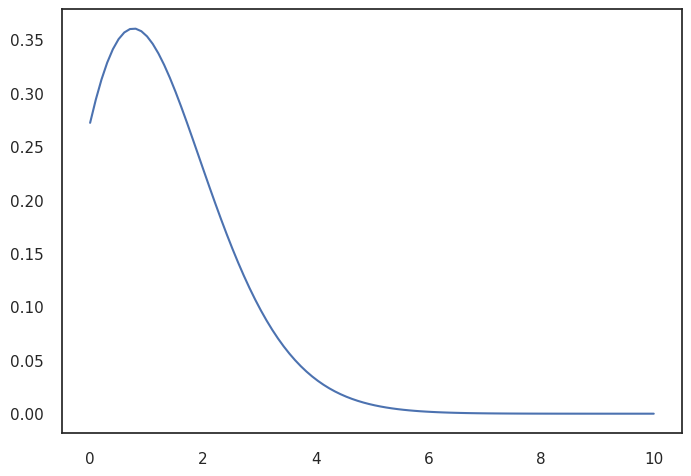

In [5]:
# test log_prob curve

from alfi.likelihood.cnb import ContinuousNegativeBinomial

test_dist = ContinuousNegativeBinomial(torch.tensor([0.0001]), torch.tensor([1.3]), validate_args=True)
x = torch.linspace(0, 10, 100, dtype=torch.float64).view(-1,1)
plt.plot(x, torch.exp(test_dist.log_prob(x)).numpy(), label='Log Probability')


findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: 

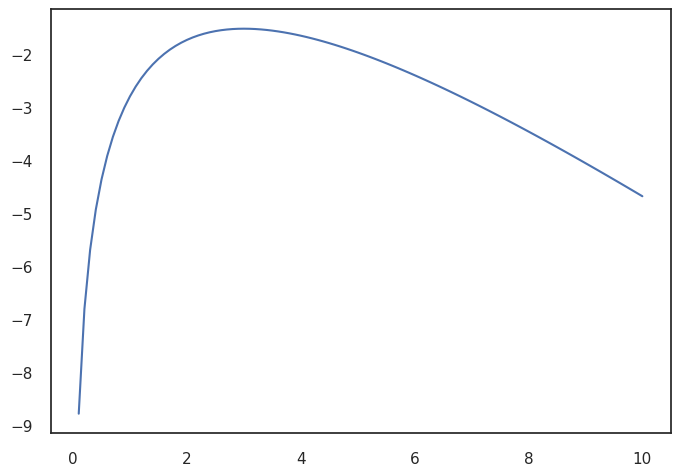

In [6]:
import numpy as np
test_dist = ContinuousNegativeBinomial(torch.tensor([0.01]), torch.linspace(0.1,10,100))
plt.plot(np.linspace(0.1, 10, 100), test_dist.log_prob(torch.tensor([3])).numpy())

In [7]:
# test expected log_prob function

from alfi.likelihood.cnb import CNegativeBinomialLikelihood

cnb_likelihood = CNegativeBinomialLikelihood(alpha=0.01, invlink=None)
x = torch.linspace(1e-5, 10, 100, dtype=torch.float64).view(-1,1)
f_var = torch.clamp(1e-7 * abs(x), min=0.01)
offset = 0
variational_dist = get_dist(x + offset, f_var)
all_zero = torch.zeros_like(f_var)
zero_dist = get_dist(all_zero + offset, f_var)
expected_log_prob = cnb_likelihood.expected_log_prob(x, zero_dist)
print(expected_log_prob.mean())

tensor(-30.2298, dtype=torch.float64, grad_fn=<MeanBackward0>)


findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: Font family 'CMU Serif' not found.
findfont: 

torch.Size([10, 1, 100])


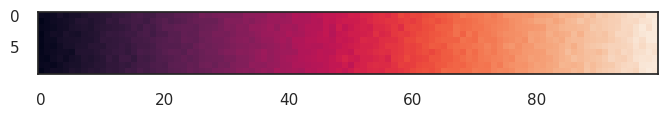

In [8]:
function_samples = variational_dist.rsample(sample_shape=torch.Size([10])) 
plt.imshow(function_samples.squeeze().numpy())
print(function_samples.shape)

In [9]:
function_samples = function_samples.squeeze()
x = x.squeeze()

In [10]:
log_probs = cnb_likelihood.forward(function_samples).log_prob(x)  # (S, T, D)
# the problem of shape should be (S,T,D) instead of (S,T,T)

In [11]:
print(log_probs.shape)

torch.Size([10, 100])


In [12]:
print(torch.where(torch.isnan(log_probs)))

(tensor([], dtype=torch.int64), tensor([], dtype=torch.int64))


In [13]:

import numpy as np
import torch

from torch.nn import Parameter
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
from pathlib import Path
from scipy.interpolate import interp1d

from torch.optim import Adam
from gpytorch.optim import NGD

from alfi.models import TrainMode, MultiOutputGP, PartialLFM, generate_multioutput_gp
from alfi.impl.pdes import ReactionDiffusion
from alfi.utilities.data import dros_ground_truth
from alfi.utilities.fenics import interval_mesh
from alfi.datasets import DrosophilaSpatialTranscriptomics, HomogeneousReactionDiffusion
from alfi.trainers import PartialPreEstimator, PDETrainer
from alfi.plot import plot_spatiotemporal_data, Plotter1d
from alfi.utilities.torch import softplus, inv_softplus
from alfi.configuration import VariationalConfiguration


In [14]:
from alfi.likelihood.cnb import CNegativeBinomialLikelihood 
from alfi.mlls import MaskedVariationalELBO
# TODO change lfm.config.num_samples will change nb_likelihood.num_likelihood_samples
class CNegativeBinomialPartialLFM(PartialLFM):
    def __init__(self, *args, nb_initial_alpha=0.2, nb_scale=None, nb_learnable_alpha=True, **kwargs):
        super().__init__(*args, **kwargs)
        # TODO change to other link function later
        self.likelihood_alt = CNegativeBinomialLikelihood(alpha=nb_initial_alpha, invlink=None, scale=nb_scale, learnable_alpha=nb_learnable_alpha)
        self.likelihood_alt.double()
        if kwargs["num_training_points"] is None:
            num_training_points = self.inducing_points.numel()
        else:
            num_training_points = kwargs["num_training_points"]
        self.loss_fn_alt = MaskedVariationalELBO(self.likelihood_alt, self.gp_model, num_training_points, combine_terms=False)

    def G(self, u):
        return softplus(u)
    def change_loss(self, likelihood=None):
        if likelihood is None:
            likelihood = self.likelihood_alt
        self.likelihood = likelihood
        self.likelihood.double()
        self.loss_fn = MaskedVariationalELBO(self.likelihood, self.gp_model, self.inducing_points.numel(), combine_terms=False)
        self.num_likelihood_samples = likelihood.num_likelihood_samples
        return self.loss_fn
        
    

## Import other modules

In [15]:
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']


In [16]:
### Load data and configuration
drosophila = True
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if drosophila:
    gene = 'kni'
    dataset = DrosophilaSpatialTranscriptomics(
        gene=gene, data_dir='./data', scale=True, disc=20) # data folder
    params = dict(lengthscale=10,
                  **dros_ground_truth(gene),
                  parameter_grad=False,
                  warm_epochs=-1,
                  natural=True,
                  zero_mean=True,
                  clamp=True)
    disc = dataset.disc
else:
    data = 'toy-spatial'
    dataset = HomogeneousReactionDiffusion(data_dir='./data')
    params = dict(lengthscale=0.2,
                  sensitivity=1,
                  decay=0.1,
                  diffusion=0.01,
                  warm_epochs=-1,
                  dp=0.025,
                  natural=True,
                  clamp=False)
    disc = 1

data = next(iter(dataset))
tx, y_target = data
lengthscale = params['lengthscale']
zero_mean = params['zero_mean'] if 'zero_mean' in params else False


Matching: True
tx torch.Size([2, 456])
torch.Size([1, 380, 2])
(53.925, 97.675)


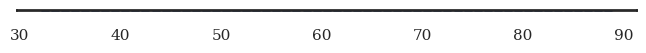

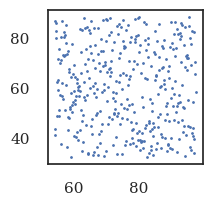

In [17]:
from dolfin import *
# We calculate a mesh that contains all possible spatial locations in the dataset

spatial = np.unique(tx[1, :])
mesh = interval_mesh(spatial)
plot(mesh)
# The mesh coordinates should match up to the data:
print('Matching:', (spatial == mesh.coordinates().reshape(-1)).all())
### Set up GP model
# Define GP
if tx.shape[1] > 1000:
    num_inducing = int(tx.shape[1] * 3/6)
else:
    num_inducing = int(tx.shape[1] * 5/6)
use_lhs = True
# whether inducing points should be sampled using LHS or random choice
if use_lhs:
    print('tx', tx.shape)
    from smt.sampling_methods import LHS
    ts = tx[0, :].unique().sort()[0].numpy()
    xs = tx[1, :].unique().sort()[0].numpy()
    xlimits = np.array([[ts[0], ts[-1]],[xs[0], xs[-1]]])
    sampling = LHS(xlimits=xlimits, random_state=np.random.RandomState(SEED))
    inducing_points = torch.tensor(sampling(num_inducing)).unsqueeze(0)
else:
    inducing_points = torch.stack([
        tx[0, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]],
        tx[1, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]]
    ], dim=1).unsqueeze(0)
gp_kwargs = dict(learn_inducing_locations=False,
                 natural=params['natural'],
                 use_tril=True)

gp_model = generate_multioutput_gp(
    1, inducing_points,
    initial_lengthscale=lengthscale,
    ard_dims=2,
    zero_mean=zero_mean,
    gp_kwargs=gp_kwargs)
# TODO tune later
gp_model.covar_module.lengthscale = lengthscale
# lengthscale_constraint=Interval(0.1, 0.3),
gp_model.double()

print(inducing_points.shape)
plt.figure(figsize=(2, 2))
plt.scatter(inducing_points[0,:,0], inducing_points[0, :, 1], s=1)
### Set up PDE (fenics module)
# Define fenics model
ts = tx[0, :].unique().sort()[0].numpy()
t_range = (ts[0], ts[-1])
print(t_range)
time_steps = dataset.num_discretised
fenics_model = ReactionDiffusion(t_range, time_steps, mesh)

config = VariationalConfiguration(
    initial_conditions=False,
    num_samples=5
)


In [18]:
## Set up the LFM

# Define LFM
parameter_grad = params['parameter_grad'] if 'parameter_grad' in params else True
sensitivity = Parameter(
    inv_softplus(torch.tensor(params['sensitivity'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=False)
decay = Parameter(
    inv_softplus(torch.tensor(params['decay'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)
diffusion = Parameter(
    inv_softplus(torch.tensor(params['diffusion'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)

fenics_params = [sensitivity, decay, diffusion]

train_ratio = 0.3
num_training = int(train_ratio * tx.shape[1])
# TODO tune alpha later
lfm = CNegativeBinomialPartialLFM(1, gp_model, fenics_model, fenics_params, config, num_training_points=num_training, nb_scale=dataset.scaler, nb_initial_alpha=0.01, nb_learnable_alpha=False)
if params['natural']:
    variational_optimizer = NGD(lfm.variational_parameters(), num_data=num_training, lr=0.015)
    parameter_optimizer = Adam(lfm.nonvariational_parameters(), lr=0.015)
    optimizers = [variational_optimizer, parameter_optimizer]
else:
    optimizers = [Adam(lfm.parameters(), lr=0.005)]

track_parameters = list(lfm.fenics_named_parameters.keys()) +\
                   list(map(lambda s: f'gp_model.{s}', dict(lfm.gp_model.named_hyperparameters()).keys()))

# As in Lopez-Lopera et al., we take 30% of data for training
train_mask = torch.zeros_like(tx[0, :])
train_mask[torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:int(train_ratio * tx.shape[1])]] = 1

orig_data = dataset.orig_data.squeeze().t()
trainer = PDETrainer(lfm, optimizers, dataset,
                     clamp=params['clamp'],
                     track_parameters=track_parameters,
                     train_mask=train_mask.bool(),
                     warm_variational=-1, # TODO tune later
                     lf_target=orig_data)
# trainer.tx is tx from the dataset, added with discreti
tx = trainer.tx
num_t_orig = orig_data[:, 0].unique().shape[0]
num_x_orig = orig_data[:, 1].unique().shape[0]
num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]

ts = tx[0, :].unique().sort()[0].numpy()
xs = tx[1, :].unique().sort()[0].numpy()
extent = [ts[0], ts[-1], xs[0], xs[-1]] # limits on the x-axis and t-axis
# NOTE can be skipped
# print(num_t_orig, num_x_orig, num_t, num_x)
print(dataset.disc)
print(dataset.num_discretised)


x dp is set to tensor(1., dtype=torch.float64)
20
140


/var/folders/75/bxpz0dmj2f54jdmkxsc585340000gp/T/ipykernel_34156/1742730316.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


torch.Size([141, 57])
torch.Size([1, 1])
num_t 141 num_x 57
num_t_orig: 8, num_x_orig: 57
torch.Size([1, 456])


/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/torchcubicspline/interpolate.py:277: UserWarning: torch.searchsorted(): boundary tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous boundary tensor if possible. This message will only appear once per program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/BucketizationUtils.h:40.)
  index = torch.bucketize(t.detach(), self._t) - 1


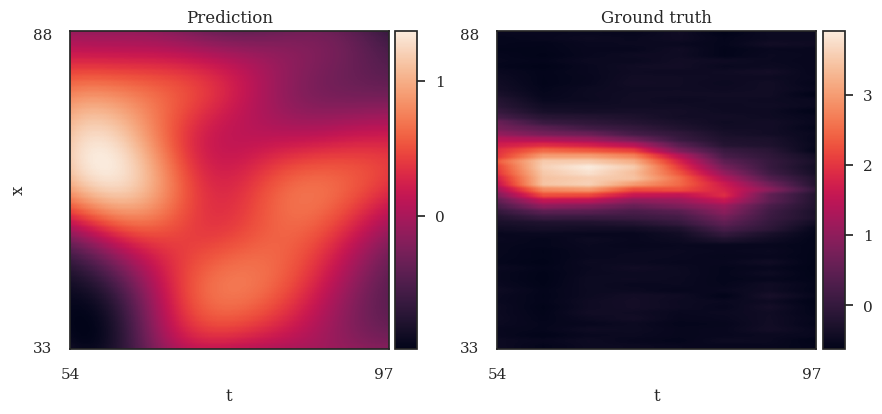

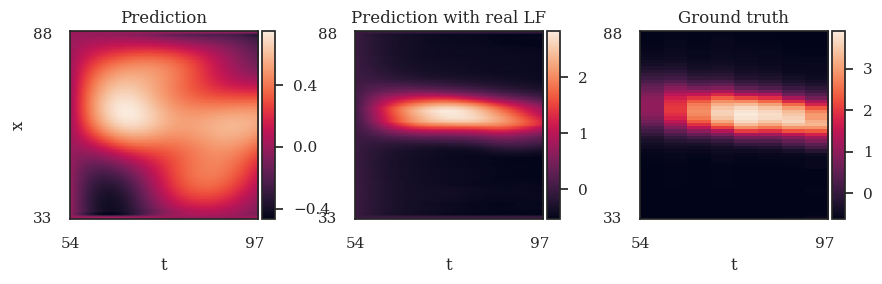

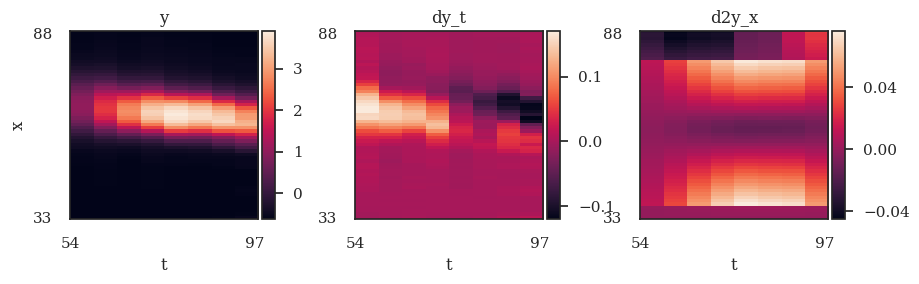

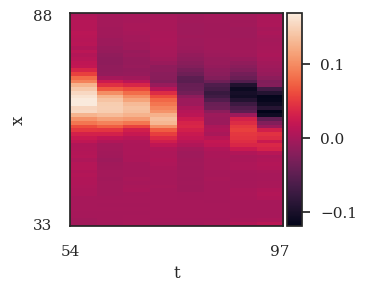

In [19]:
#### Generate output from GP prior and LFM given true/predicted latent

time = orig_data[:, 0].unique()
latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)
latent = latent.repeat(lfm.config.num_samples, 1, 1)
latent = latent.view(lfm.config.num_samples, 1, num_t_orig, num_x_orig)
time_interp = tx[0].unique()
time_interp[-1] -= 1e-5 
latent = torch.from_numpy(interp1d(time, latent, axis=2)(time_interp))

# NOTE can be skipped
# without any training, using the prior of the GP
# gp_model.covar_module.lengthscale = 0.3*0.3 * 2
out = gp_model(trainer.tx.transpose(0, 1))
sample = out.sample(torch.Size([lfm.config.num_samples])).permute(0, 2, 1)
plot_spatiotemporal_data(
    [
        sample.mean(0)[0].detach().view(num_t, num_x).t(),
        latent[0].squeeze().view(num_t, num_x).t(),
    ],
    extent,
    titles=['Prediction', 'Ground truth']
)
sample = sample.view(lfm.config.num_samples, 1, num_t, num_x)

output_pred = lfm.solve_pde(sample).mean(0)
output = lfm.solve_pde(latent).mean(0)
# NOTE can be skipped
print(output.shape)
plot_spatiotemporal_data(
    [
        output_pred.squeeze().detach().t(),
        output.squeeze().detach().t(),
        trainer.y_target.view(num_t_orig, num_x_orig).t()
    ],
    extent,
    titles=['Prediction', 'Prediction with real LF', 'Ground truth']
)
print(sensitivity.shape)
num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]
print('num_t', num_t, 'num_x', num_x)
y_target = trainer.y_target[0]
y_matrix = y_target.view(num_t_orig, num_x_orig)

pde_func, pde_target = lfm.fenics_model.interpolated_gradient(tx, y_matrix, disc=disc, plot=True)
# pde_func(y, u, sensitivity, decay, diffusion)
# pde_target = dy_t interpolated
u = orig_data[trainer.t_sorted, 2].view(num_t_orig, num_x_orig)
print(f"num_t_orig: {num_t_orig}, num_x_orig: {num_x_orig}")
u = u.view(1, -1)
print(u.shape)
# NOTE can be skipped
plot_spatiotemporal_data([pde_target.view(num_t_orig, num_x_orig).t()],
                         extent=extent, figsize=(3,3))


## Sample from NB distribution

In [20]:
# h_mean = lfm(tx)
# nb_dist = NBGaussian(
#     gaussian_dist=h_mean,
#     nb_likelihood=lfm.likelihood
# )
# # Apply sigmoid to constrain probs to [0, 1]
# nb_dist.nb_likelihood.invlink = torch.sigmoid
# nb_dist.sample(num_samples=36)

In [21]:
import gpytorch
# f_mean = torch.zeros((1, tx.shape[1]), dtype=torch.float64)  # shape (batch, times * distance)
f_mean = trainer.y_target.view(1, -1) # shape (batch, times * distance)
f_var = 1e-5 * torch.ones_like(f_mean)  # shape (batch, times * distance), increase noise, decrease loglikelihood

f_covar = torch.diag_embed(f_var)
batch_mvn = gpytorch.distributions.MultivariateNormal(f_mean, f_covar)
variational_dist = gpytorch.distributions.MultitaskMultivariateNormal.from_batch_mvn(batch_mvn, task_dim=0)

log_likelihood, kl_divergence, _ = lfm.loss_fn(variational_dist, y_target)
print(f"Log likelihood: {log_likelihood.item()}, KL divergence: {kl_divergence.item()}")

Log likelihood: -994.2534462999582, KL divergence: 1.311482616728199e-06


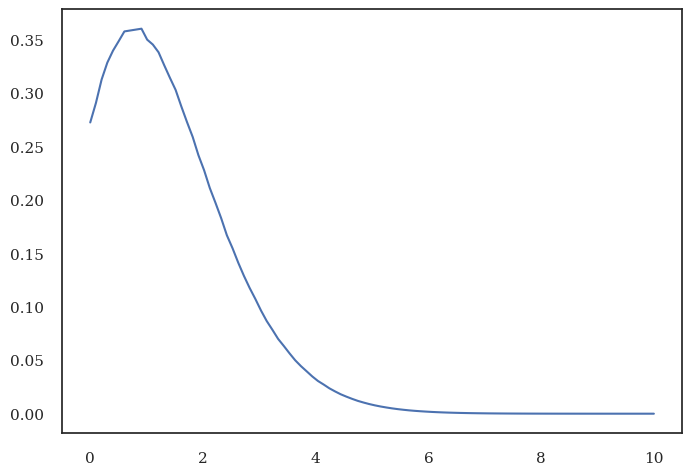

In [22]:
from alfi.likelihood.cnb import ContinuousNegativeBinomial

test_dist = ContinuousNegativeBinomial(torch.tensor([0.0001]), torch.tensor([1.3]), validate_args=True)
x = torch.linspace(0, 10, 100)
plt.plot(x, torch.exp(test_dist.log_prob(x)).numpy(), label='Log Probability')


In [23]:
skip = False
lfm.change_loss()
train_ratio = 0.3
num_training = int(train_ratio * tx.shape[1])
print(num_training)
if params['natural']:
    variational_optimizer = NGD(lfm.variational_parameters(), num_data=num_training, lr=0.03)
    parameter_optimizer = Adam(lfm.nonvariational_parameters(), lr=0.03)
    optimizers = [variational_optimizer, parameter_optimizer]
else:
    optimizers = [Adam(lfm.parameters(), lr=0.05)]


pre_estimator = PartialPreEstimator(
    lfm, optimizers, dataset, pde_func,
    input_pair=(trainer.tx, trainer.y_target), target=pde_target,
    train_mask=trainer.train_mask
)
import time
t0 = time.time()
lfm.set_mode(TrainMode.GRADIENT_MATCH)
lfm.config.num_samples = 50
# TODO change this to 80 later
if not skip:
    times = pre_estimator.train(60, report_interval=5)
lfm.config.num_samples = 5
print(tx.shape)
tx_orig = orig_data[:, :2].t()
print(tx_orig.shape)

# Compare tx and tx_orig, find the indices of tx that correspond to tx_orig
indices = torch.where(torch.all(torch.eq(tx.unsqueeze(-1), tx_orig.unsqueeze(1)), dim=0))[1]
print(tx[:, indices])
print(tx_orig[:, indices])
# the first 512 points of tx correspond to tx_orig
from alfi.utilities.torch import q2, cia
lfm.eval()
# f = lfm(tx)
f = lfm(tx)
f_mean = f.mean.detach()[:512]
f_var = f.variance.detach()[:512]
y_target = trainer.y_target[0]
# TODO find tx corresponding to y_target
print(y_target.shape)
print(tx.shape)

print(f_mean.shape, y_target.shape, f_var.shape)
print('prot Q2', q2(y_target.squeeze(), f_mean.squeeze()))
print('prot CA', cia(y_target.squeeze(), f_mean.squeeze(), f_var.squeeze()))
gp = lfm.gp_model(tx.t())
lf_target = orig_data[trainer.t_sorted, 2]
f_mean = gp.mean.detach().view(num_t, num_x)[::disc].reshape(-1)
f_var = gp.variance.detach().view(num_t, num_x)[::disc].reshape(-1)

print('mrna Q2', q2(lf_target.squeeze(), f_mean.squeeze()))
print('mrna CA', cia(lf_target.squeeze(), f_mean.squeeze(), f_var.squeeze()))


# print(np.stack(times).shape)
# plt.plot(np.stack(times)[:, 1])
print(f.variance.detach())


2411
f_mean  shape torch.Size([1, 456])
f_var shape torch.Size([1, 456])
f_covar shape torch.Size([1, 456, 456])
tensor([[0.0022, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0022, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0022, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0022, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0022, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0021, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0021, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0020, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0020,
         0.000

RuntimeError: The size of tensor a (456) must match the size of tensor b (512) at non-singleton dimension 0

In [ ]:
for name, param in lfm.named_parameters():
    print(f"Parameter: {name}, dtype: {param.dtype}")

In [ ]:
for i, optimizer in enumerate(optimizers):
    print(f"Optimizer {i}:")
    for key, value in optimizer.state.items():
        print(f"  State Key: {key}")
        for state_key, state_value in value.items():
            if isinstance(state_value, torch.Tensor):
                print(f"    {state_key}: {state_value.dtype}")

In [ ]:
lfm.likelihood.alpha

In [ ]:

# repeat untinl convergence
trainer.train(50)


In [ ]:
lfm.change_loss()
trainer.train(50)

In [ ]:
with torch.no_grad():
    lfm.config.num_samples = 5
    lfm.eval()
    u = lfm.gp_model(trainer.tx.t()).sample(torch.Size([5])).permute(0, 2, 1)
    u = u.view(*u.shape[:2], num_t, num_x)
    dy_t_ = pde_func(
        trainer.y_target,
        u[:, :, ::disc].contiguous(),
        sensitivity,
        decay,
        diffusion)[0]

    out_predicted = lfm.solve_pde(u.view(5, 1, num_t, num_x)).mean(0)

ts = tx[0, :].unique().numpy()
xs = tx[1, :].unique().numpy()
extent = [ts[0], ts[-1], xs[0], xs[-1]]
axes = plot_spatiotemporal_data(
    [
        trainer.y_target.view(num_t_orig, num_x_orig).t(),
        pde_target.reshape(num_t_orig, num_x_orig).t(),
        dy_t_.view(num_t_orig, num_x_orig).t(),
        latent[0].view(num_t, num_x).t(),
        u.mean(0).view(num_t, num_x).t(),
    ],
    extent, titles=['y', 'target dy_t', 'pred dy_t_', 'target latent', 'pred latent']
)
plot_spatiotemporal_data(
    [
        # real.t().detach(),
        trainer.y_target.view(num_t_orig, num_x_orig).t(),
        out_predicted.t().detach()
    ],
    extent, titles=['Target', 'Predicted']
)
print([softplus(param).item() for param in lfm.fenics_parameters])

In [ ]:
trainer.train(50)

In [ ]:
from pde_experiment import *
def evaluate_model(lfm, trainer, plot=False, scaler=None, path=""):
    tx = trainer.tx
    disc = trainer.disc
    h = lfm(tx, step=disc)
    f_mean = h.mean.detach()
    f_var = h.variance.detach()
    y_target = trainer.y_target[0]
    f_mean_test = f_mean.squeeze()
    f_var_test = f_var.squeeze()
    if scaler is not None:
        f_mean = torch.tensor(scaler.inverse_transform(f_mean.detach().numpy().reshape(-1, 1))).view(-1)
        y_target = torch.tensor(scaler.inverse_transform(y_target.detach().numpy().reshape(-1, 1))).view(-1)
        f_std = np.sqrt(f_var.detach().numpy())
        f_var = torch.tensor(scaler.inverse_transform(f_std.reshape(-1,1))**2).view(-1)

    prot_q2 = q2(y_target, f_mean.squeeze()).item()
    prot_cia = cia(y_target, f_mean_test, f_var_test).item()
    prot_smse = smse(y_target, f_mean_test).mean().item()

    f = lfm.gp_model(trainer.tx.t())
    lf_target = trainer.lf_target.squeeze()
    num_t = trainer.num_t
    num_x = trainer.num_x
    f_mean = f.mean.view(num_t, num_x)[::disc].reshape(-1)
    f_var = f.variance.view(num_t, num_x)[::disc].reshape(-1)
    prot_plot = None
    mrna_plot = None

    if plot:
        tx = trainer.tx
        num_t = 8
        num_x = f_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(f_mean.min(), y_target.min())
        y_max = max(f_mean.max(), y_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        prot_axes = plot_spatiotemporal_data(
            [f_mean.detach().view(num_t, num_x).t(),
             y_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )

    if scaler is not None:
        f_mean = torch.tensor(scaler.inverse_transform(f_mean.detach().numpy().reshape(-1, 1))).view(-1)
        f_mean = lfm.G(f_mean)
        lf_target = torch.tensor(scaler.inverse_transform(lf_target.detach().numpy().reshape(-1, 1))).view(-1)
        # TODO the variance should be changed accordingly
        f_std = np.sqrt(f_var.detach().numpy())
        f_var = torch.tensor(scaler.inverse_transform(f_std.reshape(-1,1))**2).view(-1)

    mrna_q2 = q2(lf_target, f_mean.squeeze()).item()
    mrna_cia = cia(lf_target, f_mean.squeeze(), f_var.squeeze()).item()
    mrna_smse = smse(lf_target, f_mean.squeeze()).mean().item()

    if plot:
        tx = trainer.tx
        num_t = 8
        num_x = f_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(f_mean.min(), lf_target.min())
        y_max = max(f_mean.max(), lf_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        mrna_axes = plot_spatiotemporal_data(
            [f_mean.detach().view(num_t, num_x).t(),
             lf_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )
    if plot:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse, prot_axes, mrna_axes
    else:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse

evaluate_model(lfm, trainer, plot=True, scaler=dataset.scaler)

In [ ]:
import gpytorch
# f_mean = torch.zeros((1, len(trainer.y_target)), dtype=torch.float64)  # shape (batch, times * distance)
f_mean = trainer.y_target.view(1, -1) # shape (batch, times * distance)
f_var = 1e-1 * torch.ones_like(f_mean)  # shape (batch, times * distance), increase noise, decrease loglikelihood
f_mean = torch.zeros_like(f_mean)
f_covar = torch.diag_embed(f_var)
batch_mvn = gpytorch.distributions.MultivariateNormal(f_mean, f_covar)
variational_dist = gpytorch.distributions.MultitaskMultivariateNormal.from_batch_mvn(batch_mvn, task_dim=0)

log_likelihood, kl_divergence, _ = lfm.loss_fn(variational_dist, y_target)
print(f"Log likelihood: {log_likelihood.item()}, KL divergence: {kl_divergence.item()}")

In [ ]:
trainer.train(100)

In [ ]:
stop_here = True
assert not stop_here

In [ ]:
lfm.change_loss()
trainer.train(300)

In [ ]:
lfm.likelihood.alpha

In [ ]:
sum(scaled_target[np.where(scaled_target < 0)])

In [ ]:
from pde_experiment import evaluate_model
evaluate_model(lfm, trainer, scaler=dataset.scaler, plot=True)

### Evaluate the mdoel

In [ ]:
# TODO write a test
from pde_experiment import evaluate_model

lfm.eval()
prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse = evaluate_model(lfm, trainer)
result_dict = {
    'prot_q2': prot_q2,
    'prot_cia': prot_cia,
    'prot_smse': prot_smse,
    'mrna_q2': mrna_q2,
    'mrna_cia': mrna_cia,
    'mrna_smse': mrna_smse
}

for key, value in result_dict.items():
    print(f"{key}: {value:.4f}")

In [ ]:

latent.shape
y_target.shape
# lfm = PartialLFM.load(filepath,
#                       gp_cls=MultiOutputGP,
#                       gp_args=[inducing_points, 1],
#                       gp_kwargs=gp_kwargs,
#                       lfm_args=[1, fenics_model, fenics_params, config])
lfm = PartialLFM(1, gp_model, fenics_model, fenics_params, config)

gp_model = lfm.gp_model
optimizer = [torch.optim.Adam(lfm.parameters(), lr=0.07)]
trainer = PDETrainer(lfm, optimizer, dataset, track_parameters=list(lfm.fenics_named_parameters.keys()), lf_target=orig_data)
from alfi.utilities.torch import smse, cia, q2

num_t = tx[0, :].unique().shape[0]
num_x = tx[1, :].unique().shape[0]
# f_mean = lfm(tx).mean.detach()
# f_var = lfm(tx).variance.detach()
y_target = trainer.y_target[0]
ts = tx[0, :].unique().sort()[0].numpy()
xs = tx[1, :].unique().sort()[0].numpy()
t_diff = ts[-1] - ts[0]
x_diff = xs[-1] - xs[0]
extent = [ts[0], ts[-1], xs[0], xs[-1]]
print(y_target.shape, f_mean.squeeze().shape)
f_mean_test = f_mean.squeeze()
f_var_test = f_var.squeeze()

print(q2(y_target, f_mean.squeeze()))
print(cia(y_target, f_mean_test, f_var_test).item())
print(smse(y_target, f_mean_test).mean().item())
plotter = Plotter1d(lfm, np.arange(1), style="seaborn-v0_8")

titles = ['Sensitivity', 'Decay', 'Diffusion']
kinetics = list()
for key in lfm.fenics_named_parameters.keys():
    kinetics.append(softplus(trainer.parameter_trace[key][-1]).squeeze().numpy())
kinetics = np.array(kinetics).reshape(3, 1)

plotter.plot_double_bar(kinetics, titles=titles)

# plotter.plot_latents()